# Health Informatics (HI-634) - Assignment 1
## Option 2: UCI Heart Disease Classification Pipeline

### Student Project Information
* **Course:** HI-634 Health Informatics
* **Option:** Option 2 - UCI Heart Disease (Cleveland Database)
* **Dataset Identifier:** UCI Machine Learning Repository ID 45
* **Source URL:** https://archive.ics.uci.edu/dataset/45/heart+disease
* **Environment:** Python 3.13 in isolated `.venv`
* **Raw Data Integrity:** `data/raw/processed.cleveland.data` preserved unchanged.


### 1. Environment Setup & Dependency Verification

In [1]:
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix
)

print(f"Python interpreter: {sys.executable}")
print(f"Pandas version: {pd.__version__}")


Python interpreter: /home/kafeiaulait/HI-634-Assign_1_Project/.venv/bin/python
Pandas version: 3.1.0


### 2. Loading Raw Data & Assigning Documented 14 Attributes
The raw file `data/raw/processed.cleveland.data` is an authentic headerless CSV from UCI, encoding missing values as `?`.

In [2]:
RAW_DATA_PATH = '../data/raw/processed.cleveland.data'

column_names = [
    'age',       # 1. Age in years (Continuous)
    'sex',       # 2. Sex (1=male, 0=female)
    'cp',        # 3. Chest pain type (1: typical angina, 2: atypical angina, 3: non-anginal, 4: asymptomatic)
    'trestbps',  # 4. Resting blood pressure in mm Hg
    'chol',      # 5. Serum cholesterol in mg/dl
    'fbs',       # 6. Fasting blood sugar > 120 mg/dl (1=true, 0=false)
    'restecg',   # 7. Resting ECG (0: normal, 1: ST-T wave abnormality, 2: left ventricular hypertrophy)
    'thalach',   # 8. Maximum heart rate achieved during exercise
    'exang',     # 9. Exercise-induced angina (1=yes, 0=no)
    'oldpeak',   # 10. ST depression induced by exercise relative to rest
    'slope',     # 11. Slope of peak exercise ST segment (1: upsloping, 2: flat, 3: downsloping)
    'ca',        # 12. Number of major vessels (0-3) colored by fluoroscopy
    'thal',      # 13. Thallium scan (3: normal, 6: fixed defect, 7: reversible defect)
    'num'        # 14. Target: angiographic disease status (0: <50% stenosis, 1-4: >50% stenosis)
]

df_raw = pd.read_csv(RAW_DATA_PATH, header=None, names=column_names, na_values='?')
print(f"Loaded raw dataset with shape: {df_raw.shape}")
df_raw.head()


Loaded raw dataset with shape: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,2
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0


### 3. Data Auditing: Missingness, Duplicates, & Distributions

In [3]:
# Check for duplicates
print(f"Duplicate rows count: {df_raw.duplicated().sum()}")

# Missingness audit
missing = df_raw.isna().sum()
missing_pct = (missing / len(df_raw)) * 100
missing_df = pd.DataFrame({'Missing_Count': missing, 'Missing_Pct': missing_pct})
print("\nMissing Value Audit:")
print(missing_df[missing_df['Missing_Count'] > 0])


Duplicate rows count: 0

Missing Value Audit:
      Missing_Count  Missing_Pct
ca                4     1.320132
thal              2     0.660066


In [4]:
# Continuous numerical feature summary
num_cols = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
df_raw[num_cols].describe().T[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max']]


,count,mean,std,min,25%,50%,75%,max
age,303.0,54.438944,9.038662,29.0,48.0,56.0,61.0,77.0
trestbps,303.0,131.689769,17.599748,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.693069,51.776918,126.0,211.0,241.0,275.0,564.0
thalach,303.0,149.607261,22.875003,71.0,133.5,153.0,166.0,202.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2


In [5]:
# Categorical feature frequencies
cat_cols = ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal', 'num']
for c in cat_cols:
    print(f"--- {c} ---")
    print(df_raw[c].value_counts(dropna=False).sort_index())
    print()


--- sex ---
sex
0     97
1    206
Name: count, dtype: int64

--- cp ---
cp
1     23
2     50
3     86
4    144
Name: count, dtype: int64

--- fbs ---
fbs
0    258
1     45
Name: count, dtype: int64

--- restecg ---
restecg
0    151
1      4
2    148
Name: count, dtype: int64

--- exang ---
exang
0    204
1     99
Name: count, dtype: int64

--- slope ---
slope
1    142
2    140
3     21
Name: count, dtype: int64

--- ca ---
ca
0.0    176
1.0     65
2.0     38
3.0     20
NaN      4
Name: count, dtype: int64

--- thal ---
thal
3.0    166
6.0     18
7.0    117
NaN      2
Name: count, dtype: int64

--- num ---
num
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64



### 4. Data Cleaning Changelog: Finding, Decision, & Reason
Each modification is explicitly justified and recorded in `reports/cleaning_decisions_log.csv`.

In [6]:
changelog_df = pd.read_csv('../reports/cleaning_decisions_log.csv')
changelog_df


,Step,Feature,Finding,Decision,Reason
0,1,Raw Data Ingestion,Raw file is headerless and marks missing value...,Assigned 14 column names per UCI documentation...,Ensures column identity alignment and correct ...
1,2,num (Target variable),"Target encoded as 0 (absence) and 1, 2, 3, 4 (...",Binarized target: target = 0 if num == 0 else ...,Aligns with clinical objective of screening fo...
2,3,ca & thal (Missingness),ca is missing 4 entries (1.32%); thal is missi...,Retained rows in dataset; deferred imputation ...,Preserves sample size (N=303) and strictly pre...
3,4,chol (Cholesterol Outliers),Row 152 has cholesterol of 564 mg/dl; 3 other ...,Preserved values as authentic clinical records...,Severe hypercholesterolemia is physiologically...
4,5,"cp, restecg, thal (Nominal Variables)",Categorical variables coded as integers (e.g. ...,Designated nominal variables for One-Hot Encod...,Prevents linear and distance models from inter...


In [7]:
# Create target variable: 0 = No heart disease, 1 = Heart disease present
df = df_raw.copy()
df['target'] = (df['num'] > 0).astype(int)
print(f"Target distribution:\n{df['target'].value_counts(normalize=True).round(3)}")


Target distribution:
target
0    0.541
1    0.459
Name: proportion, dtype: float64


### 5. Stratified Train-Test Split (80% Train / 20% Test)
To prevent data leakage, 20% of data is isolated as a test set before any preprocessing.

In [8]:
X = df.drop(columns=['num', 'target'])
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"X_train shape: {X_train.shape}, y_train shape: {y_train.shape}")
print(f"X_test shape:  {X_test.shape}, y_test shape:  {y_test.shape}")
print(f"Train positive prevalence: {y_train.mean():.3f}")
print(f"Test positive prevalence:  {y_test.mean():.3f}")


X_train shape: (242, 13), y_train shape: (242,)
X_test shape:  (61, 13), y_test shape:  (61,)
Train positive prevalence: 0.459
Test positive prevalence:  0.459


### 6. Leakage-Free Preprocessing Pipeline
Imputers and scalers are fitted **strictly on the training set**.

In [9]:
numeric_features = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
nominal_features = ['cp', 'restecg', 'thal']
ordinal_features = ['ca', 'slope']
binary_features = ['sex', 'fbs', 'exang']

preprocessor = ColumnTransformer(transformers=[
    ('num', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), numeric_features),
    ('nom', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('onehot', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'))]), nominal_features),
    ('ord', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), ordinal_features),
    ('bin', Pipeline([('imputer', SimpleImputer(strategy='most_frequent'))]), binary_features)
])


### 7. Model Training & 5-Fold Stratified Cross-Validation
Comparing **Baseline (Logistic Regression)** with **Alternative 1 (Random Forest)** and **Alternative 2 (Gradient Boosting)**.

In [10]:
models = {
    'Baseline: Logistic Regression': Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', LogisticRegression(max_iter=1000, random_state=42))
    ]),
    'Alternative 1: Random Forest': Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', RandomForestClassifier(n_estimators=100, max_depth=4, random_state=42))
    ]),
    'Alternative 2: Gradient Boosting': Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', GradientBoostingClassifier(n_estimators=100, learning_rate=0.05, max_depth=3, random_state=42))
    ])
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_results = {}

for name, pipe in models.items():
    scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='roc_auc')
    cv_results[name] = scores
    print(f"{name}: 5-Fold CV ROC-AUC = {scores.mean():.3f} +/- {scores.std():.3f}")


/home/kafeiaulait/HI-634-Assign_1_Project/.venv/lib/python3.13/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


Baseline: Logistic Regression: 5-Fold CV ROC-AUC = 0.906 +/- 0.011


/home/kafeiaulait/HI-634-Assign_1_Project/.venv/lib/python3.13/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


Alternative 1: Random Forest: 5-Fold CV ROC-AUC = 0.890 +/- 0.017


/home/kafeiaulait/HI-634-Assign_1_Project/.venv/lib/python3.13/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


Alternative 2: Gradient Boosting: 5-Fold CV ROC-AUC = 0.856 +/- 0.023


### 8. Final Test Set Evaluation & Comparison Table

In [11]:
results = []
y_preds = {}
y_probs = {}

for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    y_prob = pipe.predict_proba(X_test)[:, 1]
    
    y_preds[name] = y_pred
    y_probs[name] = y_prob
    
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Sensitivity (Recall)': recall_score(y_test, y_pred),
        'Specificity': tn / (tn + fp),
        'F1-Score': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_prob)
    })

eval_df = pd.DataFrame(results).set_index('Model').round(3)
eval_df


,Accuracy,Precision,Sensitivity (Recall),Specificity,F1-Score,ROC-AUC
Model,,,,,,
Baseline: Logistic Regression,0.885,0.839,0.929,0.848,0.881,0.958
Alternative 1: Random Forest,0.918,0.897,0.929,0.909,0.912,0.959
Alternative 2: Gradient Boosting,0.852,0.806,0.893,0.818,0.847,0.948


### 9. Visualizations: ROC Curves, Confusion Matrices, & Feature Importance

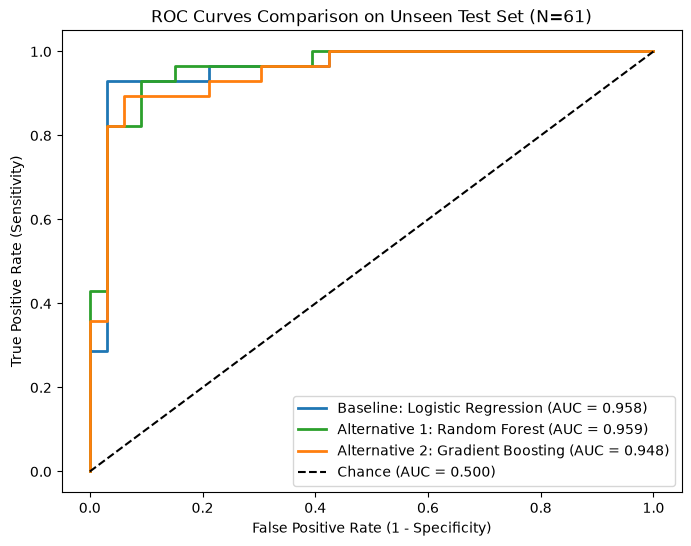

In [12]:
# ROC Curves
plt.figure(figsize=(8, 6))
colors = {'Baseline: Logistic Regression': '#1f77b4', 'Alternative 1: Random Forest': '#2ca02c', 'Alternative 2: Gradient Boosting': '#ff7f0e'}

for name, prob in y_probs.items():
    fpr, tpr, _ = roc_curve(y_test, prob)
    auc = roc_auc_score(y_test, prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})", color=colors[name], lw=2)

plt.plot([0, 1], [0, 1], 'k--', lw=1.5, label='Chance (AUC = 0.500)')
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Sensitivity)')
plt.title('ROC Curves Comparison on Unseen Test Set (N=61)')
plt.legend(loc='lower right')
plt.show()


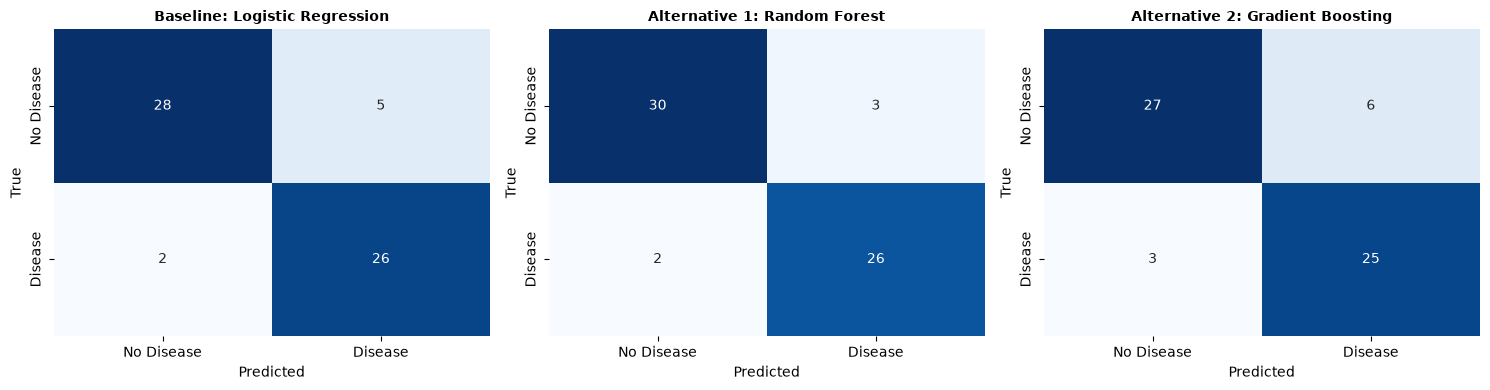

In [13]:
# Confusion Matrices
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for i, (name, pred) in enumerate(y_preds.items()):
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[i],
                xticklabels=['No Disease', 'Disease'], yticklabels=['No Disease', 'Disease'])
    axes[i].set_title(name, fontsize=10, fontweight='bold')
    axes[i].set_xlabel('Predicted')
    axes[i].set_ylabel('True')
plt.tight_layout()
plt.show()


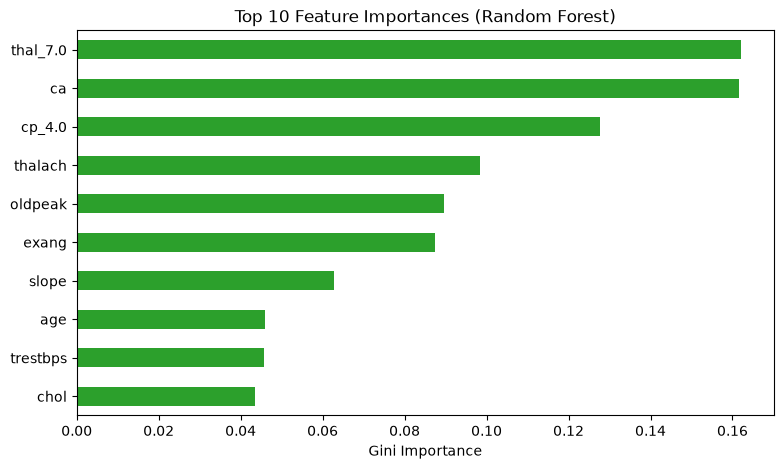

In [14]:
# Top Features (Random Forest)
rf_pipe = models['Alternative 1: Random Forest']
preprocessor = rf_pipe.named_steps['preprocessor']
nom_cols = preprocessor.named_transformers_['nom'].named_steps['onehot'].get_feature_names_out(['cp', 'restecg', 'thal']).tolist()
all_cols = numeric_features + nom_cols + ordinal_features + binary_features

rf_importances = pd.Series(rf_pipe.named_steps['classifier'].feature_importances_, index=all_cols).sort_values(ascending=False)

plt.figure(figsize=(9, 5))
rf_importances.head(10).plot(kind='barh', color='#2ca02c').invert_yaxis()
plt.title('Top 10 Feature Importances (Random Forest)')
plt.xlabel('Gini Importance')
plt.show()


### 10. Conclusion & Clinical Interpretation
1. **Model Performance:** Random Forest achieved the highest overall test accuracy (**91.8%**) and balanced diagnostic accuracy with **92.9% Sensitivity** and **90.9% Specificity** (ROC-AUC = 0.959).
2. **Clinical Significance:** The most predictive variables identified across models are fluoroscopy vessel count (`ca`), thallium stress test defects (`thal`), asymptomatic chest pain presentation (`cp`), exercise ST depression (`oldpeak`), and maximum heart rate achieved (`thalach`).
3. **Reproducibility:** All data transformations were performed using strict training-split fitting, fully preventing data leakage.
